# Time Aware AutoEncoder (TAE)

## Imports

In [1]:
from src.autoencoder import *
from src.dataset import *
from src.visualization import *
from src.embedding_utils import *

from torch.utils.data import DataLoader
from torch import optim
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
store = zarr.open("pusht/pusht_cchi_v7_replay.zarr", mode="r")

## Baseline - Not Time Aware

### Model Training


Starting Standard Autoencoder Training...
Epoch 1/1, Batch 0/3, Loss: 0.295969

--- Epoch 1 finished. Avg Loss: 0.260737 ---



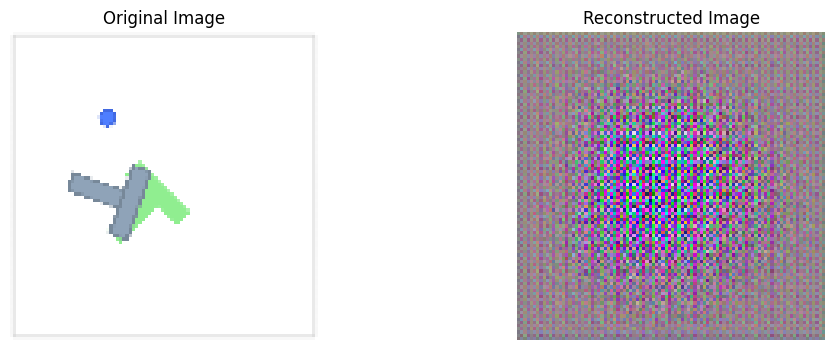

Standard Autoencoder Training Complete.


In [2]:
# Example Initialization:
dataset = ZarrDataset("pusht/pusht_cchi_v7_replay.zarr", nepisodes=1)
loader = DataLoader(dataset, batch_size=64, num_workers=0, shuffle=True)
encoder = Encoder(in_channels=3, z_dim=256)
decoder = Decoder(out_channels=3, z_dim=256)
autoencoder = StandardAutoencoder(encoder, decoder).to(DEVICE)
criterion = nn.MSELoss() # Reconstruction Loss (MSE is standard)
optimizer = optim.Adam(autoencoder.parameters(), lr=1e-3)

NUM_EPOCHS = 1

def train_standard_ae(model, dataloader, criterion, optimizer, device, num_epochs):
    print("\nStarting Standard Autoencoder Training...")
    
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0
        
        for batch_idx, x_i in enumerate(dataloader):
            # x_i is the single frame (Frame i)
            x_i = x_i.to(device)

            optimizer.zero_grad()
            
            # 1. Forward Pass
            z_i, x_prime_i = model(x_i)
            
            # 2. Calculate Loss
            loss = criterion(x_prime_i, x_i)
            
            # 3. Backpropagation
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
            # Print status periodically
            if batch_idx % 50 == 0:
                print(f"Epoch {epoch+1}/{num_epochs}, Batch {batch_idx}/{len(dataloader)}, Loss: {loss.item():.6f}")

        avg_epoch_loss = epoch_loss / len(dataloader)
        print(f"\n--- Epoch {epoch+1} finished. Avg Loss: {avg_epoch_loss:.6f} ---\n")
        plot_rec(x_i[0].permute(1, 2, 0).detach(), x_prime_i[0].permute(1, 2, 0).detach())

# --- Run the Training ---
train_standard_ae(autoencoder, loader, criterion, optimizer, DEVICE, NUM_EPOCHS)
print("Standard Autoencoder Training Complete.")
# torch.save(autoencoder.state_dict(), "standard_autoencoder.pth")

### Visualize Embedding Results

Model loaded.
Generated embeddings shape: torch.Size([161, 256])
Min_similarity: 0.0000


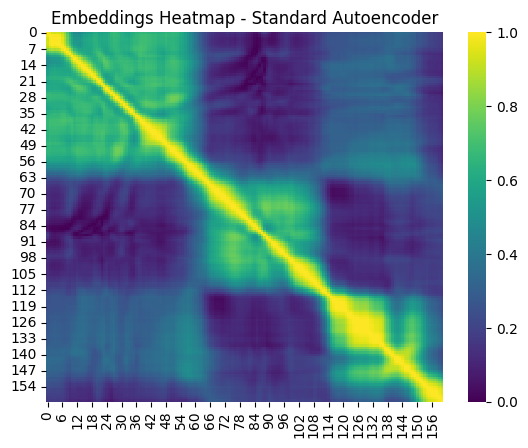

In [ ]:
encoder = Encoder(in_channels=3, z_dim=256)
decoder = Decoder(out_channels=3, z_dim=256)
autoencoder = StandardAutoencoder(encoder, decoder).to(DEVICE)
state_dict_A = torch.load("checkpoints/standard_autoencoder.pth", map_location=torch.device('cpu'))
# state_dict_B = autoencoder.state_dict()
# pretrained_dict = {k: v for k, v in state_dict_A.items() if k in state_dict_B and v.shape == state_dict_B[k].shape}
autoencoder.load_state_dict(state_dict_A)
print("Model loaded.")

dataset = ZarrDataset("pusht/pusht_cchi_v7_replay.zarr", nepisodes=1)
loader = DataLoader(dataset, batch_size=64, num_workers=0, shuffle=False)
embeddings = embs_from_dataloader(autoencoder, loader, DEVICE)
print(f"Generated embeddings shape: {embeddings.shape}") 
emb_hmap(embeddings[:161], title="Embeddings Heatmap - Standard Autoencoder")

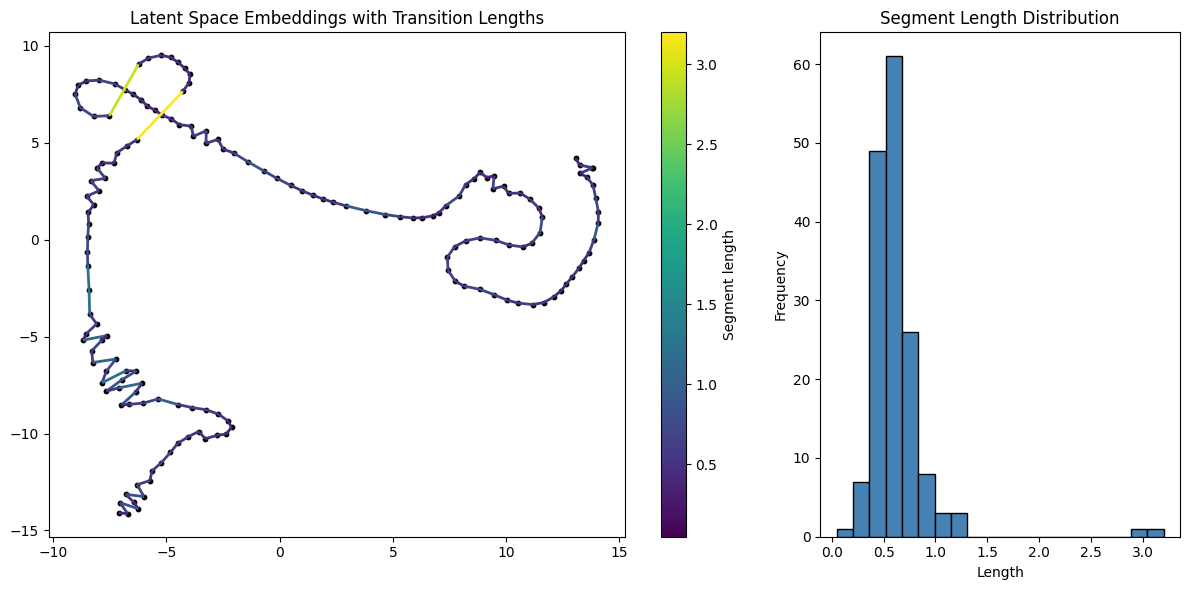

In [72]:
plot_2d_embeddings(embeddings[:161].numpy(), "Latent Space Embeddings with Transition Lengths")

### Evaluate Model

In [73]:
data_test = store["data/img"][1684:1824]
data_test = np.ascontiguousarray(np.transpose(data_test, (0, 3, 1, 2)))/255.0
data_test = torch.from_numpy(data_test).float().to(DEVICE)
z_test, recon_test = autoencoder(data_test)
error = F.mse_loss(recon_test, data_test)
print(f"Test Reconstruction Error (MSE): {error.item():.6f}")

Test Reconstruction Error (MSE): 0.000219


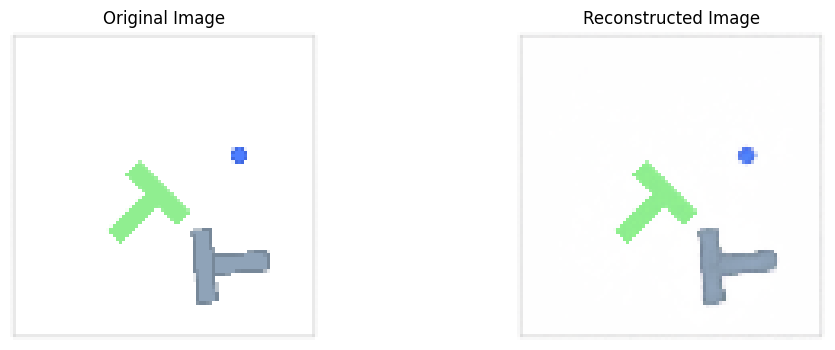

In [74]:
plot_rec(data_test[0].permute(1, 2, 0), recon_test[0].permute(1, 2, 0).detach())

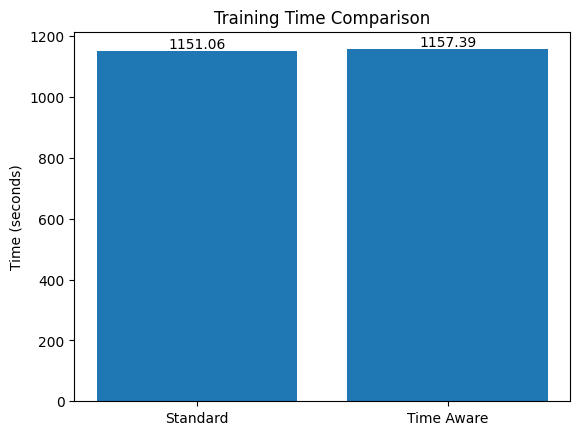

In [ ]:
names = ["Standard", "Time Aware"]
times = [1151.06, 1157.39]

plt.bar(names, times)
plt.ylabel("Time (seconds)")
for i in range(len(times)):
    plt.text(names[i], times[i]+10, f"{times[i]:.2f}", ha='center')

plt.title("Training Time Comparison")
plt.show()


## Time Aware Embeddings

### Model Training


Starting Time-Aware Autoencoder Training...
x_i shape: torch.Size([64, 3, 96, 96]), x_i_plus_1 shape: torch.Size([64, 3, 96, 96])
Epoch 1/1, Batch 0/3, Total Loss: 0.68585
x_i shape: torch.Size([64, 3, 96, 96]), x_i_plus_1 shape: torch.Size([64, 3, 96, 96])
x_i shape: torch.Size([32, 3, 96, 96]), x_i_plus_1 shape: torch.Size([32, 3, 96, 96])

--- Epoch 1 Finished. Avg Total Loss: 0.86743 ---



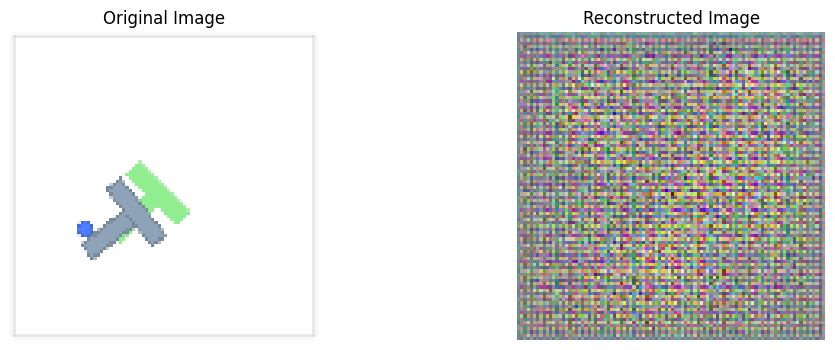

In [2]:
lambda_id = 1.0  # Weight for Identity Reconstruction Loss
lambda_cons = 0.5  # Weight for Consistency Loss

def train_time_aware_autoencoder(model, dataloader, criterion, optimizer, device, num_epochs):
    print("\nStarting Time-Aware Autoencoder Training...")
    
    # 1. Set model to training mode
    for epoch in range(num_epochs):
        model.train() 
        epoch_loss = 0

        # dataloader yields (x_i, x_i_plus_1)
        for batch_idx, data in enumerate(dataloader):
            # Move data to device
            x_i = data[:,0].to(device).float()
            x_i_plus_1 = data[:,1].to(device).float()
            print(f"x_i shape: {x_i.shape}, x_i_plus_1 shape: {x_i_plus_1.shape}" )

            optimizer.zero_grad()
            
            # 2. Forward Pass: Computes all five required outputs
            outputs = model(x_i, x_i_plus_1)
            
            # 3. Calculate the Loss Terms
            
            # A. Identity Reconstruction Loss (L_ID)
            L_Identity = criterion(outputs[1], x_i) + criterion(outputs[4], x_i_plus_1)
            
            # B. Consistency Loss (L_Cons)
            L_Cons = criterion(outputs[2], outputs[3])
            

            # 4. Total Loss and Optimization
            total_batch_loss = (lambda_id * L_Identity) + (lambda_cons * L_Cons)
            # print(total_batch_loss)
            total_batch_loss.backward()
            optimizer.step()
            
            epoch_loss += total_batch_loss.item()
            
            if batch_idx % 10 == 0:
                print(f"Epoch {epoch+1}/{num_epochs}, Batch {batch_idx}/{len(dataloader)}, Total Loss: {total_batch_loss.item():.5f}")

        avg_epoch_loss = epoch_loss / len(dataloader)
        print(f"\n--- Epoch {epoch+1} Finished. Avg Total Loss: {avg_epoch_loss:.5f} ---\n")
        plot_rec(x_i[0].permute(1, 2, 0).detach(), outputs[1][0].permute(1, 2, 0).detach())



encoder = Encoder(in_channels=3, z_dim=256)
decoder = Decoder(out_channels=3, z_dim=256)
model = TimeAwareAutoencoder(encoder, decoder).to(DEVICE)
dataset = ZarrPairwiseDataset("pusht/pusht_cchi_v7_replay.zarr", nepisodes=1)
dataloader = DataLoader(dataset, batch_size=64, num_workers=0, shuffle=False)
criterion = nn.MSELoss() # Reconstruction Loss (MSE is standard)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
NUM_EPOCHS = 1

train_time_aware_autoencoder(model, dataloader, criterion, optimizer, DEVICE, NUM_EPOCHS)
# torch.save(model.state_dict(), "consistency_autoencoder.pth")

### Visualize Embedding Results

Model loaded.
Generated embeddings shape: torch.Size([161, 256])
Min_similarity: 0.0000


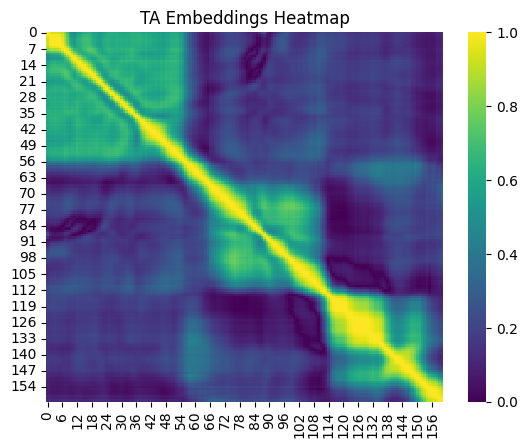

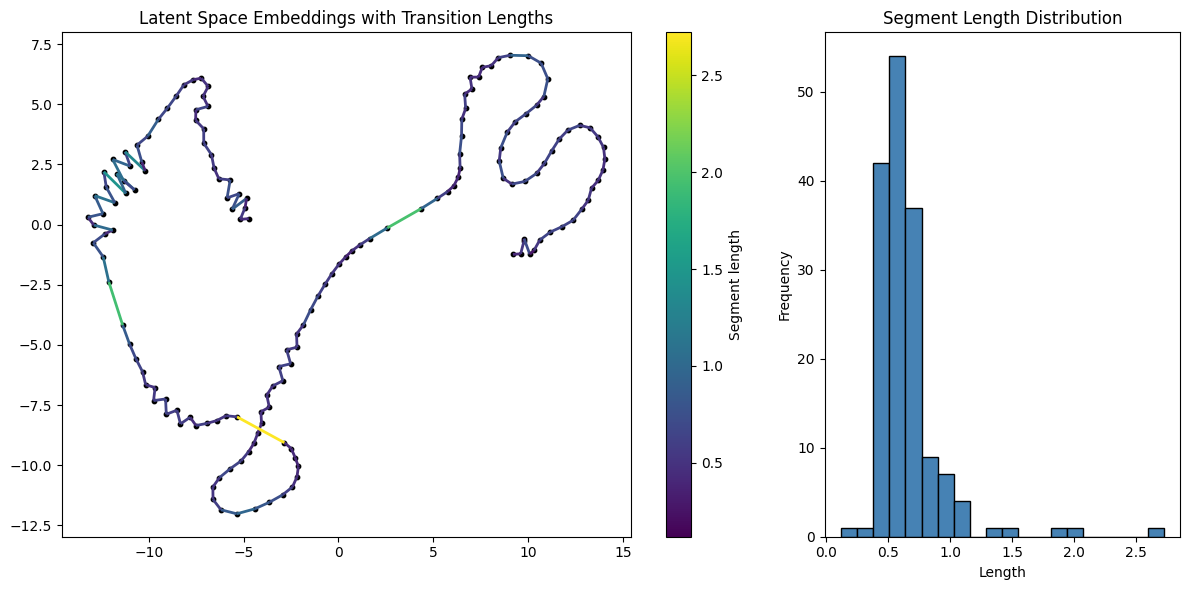

In [ ]:
encoder = Encoder(in_channels=3, z_dim=256)
decoder = Decoder(out_channels=3, z_dim=256)
ta_autoencoder = TimeAwareAutoencoder(encoder, decoder).to(DEVICE)
state_dict_A = torch.load("checkpoints/ta_autoencoder.pth", map_location=torch.device('cpu'))
state_dict_B = ta_autoencoder.state_dict()
pretrained_dict = {k: v for k, v in state_dict_A.items() if k in state_dict_B and v.shape == state_dict_B[k].shape}
state_dict_B.update(pretrained_dict)
ta_autoencoder.load_state_dict(state_dict_B)
print("Model loaded.")

dataset = ZarrDataset("pusht/pusht_cchi_v7_replay.zarr", nepisodes=1)
dataloader = DataLoader(dataset, batch_size=64, num_workers=0, shuffle=False)
ta_embeddings = embs_from_dataloader(ta_autoencoder, dataloader, DEVICE)
print(f"Generated embeddings shape: {ta_embeddings.shape}") 
# Expected shape: (Total_Frames_in_Dataset, 256)
emb_hmap(ta_embeddings[:161], "TA Embeddings Heatmap")
plot_2d_embeddings(ta_embeddings[:161].numpy(), "Latent Space Embeddings with Transition Lengths")

### Evaluate Model

In [4]:
data_test = store["data/img"][1684:1824]
data_test = np.ascontiguousarray(np.transpose(data_test, (0, 3, 1, 2)))/255.0
data_test = torch.from_numpy(data_test).float().to(DEVICE)
output = ta_autoencoder(data_test)[1]
error = F.mse_loss(output, data_test)
print(f"Test Reconstruction Error (MSE): {error.item():.6f}")

Test Reconstruction Error (MSE): 0.000160


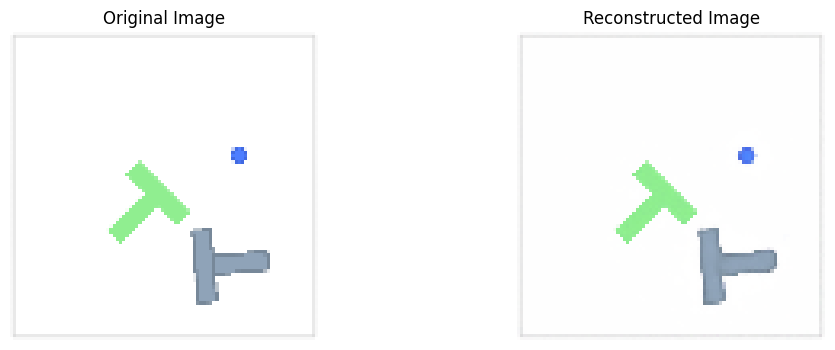

In [38]:
plot_rec(data_test[0].permute(1, 2, 0), output[0].permute(1, 2, 0).detach())

In [6]:
data_test = store["data/img"][1684:1824]
data_test = np.ascontiguousarray(np.transpose(data_test, (0, 3, 1, 2)))/255.0
data_test = torch.from_numpy(data_test).float().to(DEVICE)
output = ta_autoencoder(data_test)

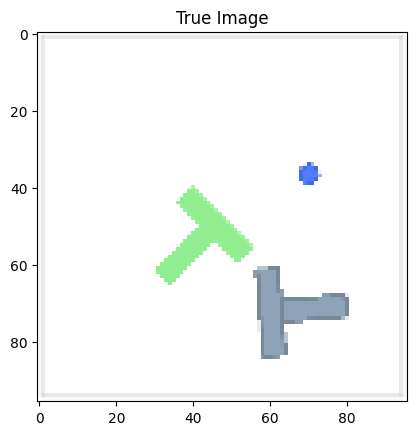

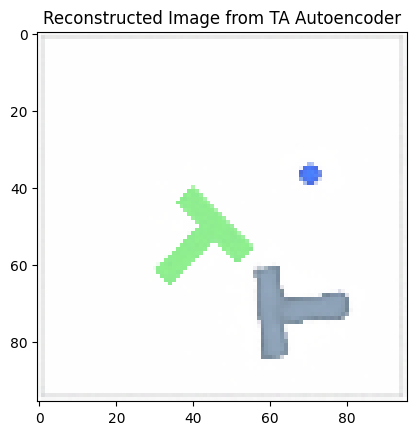

Text(0.5, 1.0, 'Predicted Next Frame from TA Autoencoder')

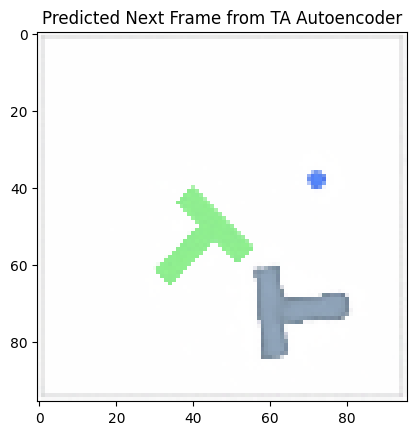

In [7]:
embs = output[0]
recon = output[1]

plt.imshow(data_test[1].permute(1, 2, 0).detach().cpu())
plt.title("True Image")
plt.show()

plt.imshow(recon[1].permute(1, 2, 0).detach().cpu())
plt.title("Reconstructed Image from TA Autoencoder")
plt.show()

ta_autoencoder.eval()
with torch.no_grad():
    z_test, _ = ta_autoencoder(data_test[0].unsqueeze(0))
    z_test_plus_1 = ta_autoencoder.MLP(z_test)
    recon_test = ta_autoencoder.decoder(z_test_plus_1)

plt.imshow(recon_test[0].permute(1, 2, 0).detach().cpu())
plt.title("Predicted Next Frame from TA Autoencoder")


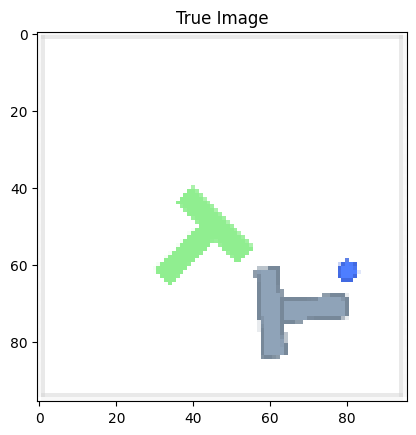

Text(0.5, 1.0, 'Predicted Frame n from TA Autoencoder')

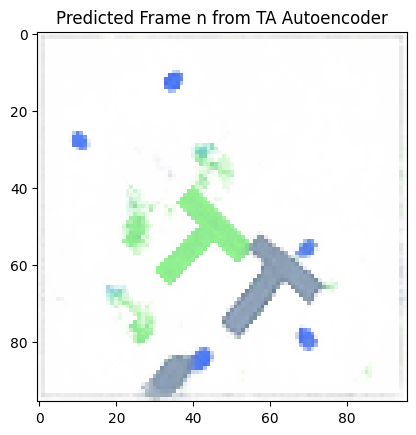

In [86]:
embs = output[0]
recon = output[1]

n = 12

plt.imshow(data_test[n].permute(1, 2, 0).detach().cpu())
plt.title("True Image")
plt.show()

ta_autoencoder.eval()
with torch.no_grad():
    z_test, _ = ta_autoencoder(data_test[0].unsqueeze(0))
    for i in range(n):
        z_test = ta_autoencoder.MLP(z_test)
    recon_test = ta_autoencoder.decoder(z_test)

plt.imshow(recon_test[0].permute(1, 2, 0).detach().cpu())
plt.title("Predicted Frame n from TA Autoencoder")